In [1]:

#Find dataset paths
from pathlib import Path

# List all CSV files in Kaggle Input
for path in Path("/kaggle/input").rglob("*.csv"):
    print(path)

import pandas as pd
import numpy as np
import json

from pathlib import Path

from sklearn.model_selection import (
    PredefinedSplit,
    RandomizedSearchCV,
    cross_validate,
    cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

# Automatically locate the two datasets
csv_files = list(Path("/kaggle/input").rglob("*.csv"))

train_paths = [p for p in csv_files if p.name == "train_folds.csv"]
test_paths = [p for p in csv_files if p.name == "test.csv"]

assert len(train_paths) == 1, f"Train paths: {train_paths}"
assert len(test_paths) == 1, f"Test paths: {test_paths}"

train = pd.read_csv(train_paths[0])
test = pd.read_csv(test_paths[0])

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(test.head())


/kaggle/input/datasets/bchtrnng/test-csv/test.csv
/kaggle/input/datasets/bchtrnng/train-folds/train_folds.csv
Train shape: (143771, 18)
Test shape: (70814, 17)


,add_count,remove_count,unique_products_in_cart,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,nevents,unique_products_viewed,avg_dwell_time,session_duration,hod,dow,SCA,fold
0,1,1,1,24,0,1.000000,5,0,7.0,7.0,26,0,30.422320,760.558,12,4,0,9
1,2,0,2,10,4,0.400000,0,1,3.0,3.0,16,2,95.361364,1048.975,7,4,0,6
2,1,3,1,26,4,0.200000,1,2,4.0,8.0,34,4,41.664793,1208.279,7,3,1,6
3,1,1,1,43,18,0.052632,0,1,10.0,10.0,63,5,21.466091,944.508,9,2,1,7
4,1,0,1,67,10,0.090909,2,3,8.0,10.0,78,9,28.922493,1937.807,20,7,0,5


,add_count,remove_count,unique_products_in_cart,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,nevents,unique_products_viewed,avg_dwell_time,session_duration,hod,dow,SCA
0,2,1,2,18,3,0.50,0,2,7.0,7.0,24,3,56.669500,1133.390,10,3,0
1,3,19,1,16,4,0.60,0,1,10.0,10.0,42,2,12.364811,457.498,7,6,0
2,1,0,1,3,1,0.50,0,1,7.0,7.0,5,1,23.527333,70.582,10,5,1
3,1,0,1,7,3,0.25,0,1,8.0,9.0,11,2,10.602143,74.215,15,7,1
4,1,1,1,19,3,0.25,1,1,10.0,10.0,24,3,143.245350,2864.907,10,4,1


In [2]:
 #Feature selection

features = [
    "add_count",
    "remove_count",
    "view_count",
    "detail_count",
    "add_to_detail_ratio",
    "search_count",
    "unique_categories_viewed",
    "avg_price_bucket",
    "max_price_bucket",
    "unique_products_viewed",
    "avg_dwell_time",
    "session_duration",
    "hod",
    "dow"
]

target = "SCA"

# Verify the required columns exist
assert set(features + [target, "fold"]).issubset(train.columns)
assert set(features + [target]).issubset(test.columns)

# Confirm expected row counts
assert len(train) == 143771
assert len(test) == 70814

# Select X and y
X_train = train[features].copy()
y_train = train[target].astype(int)

X_test = test[features].copy()
y_test = test[target].astype(int)

assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
#Check missing values

print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in test data:")
print(X_test.isnull().sum())


X_train: (143771, 14)
y_train: (143771,)
X_test: (70814, 14)
y_test: (70814,)
Missing values in training data:
add_count                     0
remove_count                  0
view_count                    0
detail_count                  0
add_to_detail_ratio           0
search_count                  0
unique_categories_viewed      0
avg_price_bucket            147
max_price_bucket            134
unique_products_viewed        0
avg_dwell_time                0
session_duration              0
hod                           0
dow                           0
dtype: int64

Missing values in test data:
add_count                    0
remove_count                 0
view_count                   0
detail_count                 0
add_to_detail_ratio          0
search_count                 0
unique_categories_viewed     0
avg_price_bucket            70
max_price_bucket            64
unique_products_viewed       0
avg_dwell_time               0
session_duration             0
hod                       

In [3]:
#Create Pipeline

pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
            tree_method="hist"
        )
    )
])

print(pipeline)
#PredefinedSplit

cv = PredefinedSplit(
    test_fold=train["fold"].to_numpy()
)

print("Number of folds:", cv.get_n_splits())

for fold, (train_idx, val_idx) in enumerate(
    cv.split()
):
    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(val_idx)}"
    )


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
      

In [4]:
#Define hyperparameter search space

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5, 10]
}
#Run RandomizedSearchCV


from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
import pandas as pd

# RMSE calculated using predicted probabilities
def rmse_proba(y_true, y_proba):
    return float(
        np.sqrt(mean_squared_error(y_true, y_proba))
    )

# Use predict_proba instead of predict
RMSE_PROBA = make_scorer(
    rmse_proba,
    response_method="predict_proba",
    greater_is_better=False
)

# Hyperparameter search space
param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5, 10]
}

# Randomized Search with probability RMSE
search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring={
        "rmse": RMSE_PROBA,
        "auc": "roc_auc"
    },
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit="rmse",
    verbose=2,
    return_train_score=False
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("\nBest CV Probability RMSE:")
print(-search.best_score_)

# Display top 10 tuning results
tuning_results = pd.DataFrame(search.cv_results_)

tuning_results["rmse"] = (
    -tuning_results["mean_test_rmse"]
)

top10 = tuning_results.sort_values(
    "rmse", ascending=True
).head(10)

display(
    top10[
        [
            "rank_test_rmse",
            "rmse",
            "std_test_rmse",
            "mean_test_auc",
            "params"
        ]
    ]
)

best_model = search.best_estimator_

print("\nBest model:")
print(best_model)



Fitting 10 folds for each of 30 candidates, totalling 300 fits
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=3, model__n_estimators=200, model__reg_lambda=10, model__subsample=0.9; total time=   3.5s
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=3, model__n_estimators=200, model__reg_lambda=10, model__subsample=0.9; total time=   3.4s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.03, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__reg_lambda=10, model__subsample=0.7; total time=   7.7s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.03, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__reg_lambda=10, model__subsample=0.7; total time=   7.6s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.03, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, 

,rank_test_rmse,rmse,std_test_rmse,mean_test_auc,params
16,1,0.375004,0.000911,0.775361,"{'model__subsample': 0.8, 'model__reg_lambda':..."
29,2,0.375322,0.000962,0.774397,"{'model__subsample': 0.8, 'model__reg_lambda':..."
10,3,0.375338,0.000907,0.774254,"{'model__subsample': 1.0, 'model__reg_lambda':..."
5,4,0.375462,0.000955,0.773928,"{'model__subsample': 0.9, 'model__reg_lambda':..."
2,5,0.375519,0.000924,0.773560,"{'model__subsample': 0.9, 'model__reg_lambda':..."
12,6,0.375536,0.000870,0.773496,"{'model__subsample': 0.9, 'model__reg_lambda':..."
28,7,0.375664,0.000812,0.773205,"{'model__subsample': 0.9, 'model__reg_lambda':..."
11,8,0.375721,0.000884,0.772769,"{'model__subsample': 1.0, 'model__reg_lambda':..."
20,9,0.375818,0.000872,0.773051,"{'model__subsample': 0.7, 'model__reg_lambda':..."
4,10,0.375839,0.000896,0.772413,"{'model__subsample': 0.7, 'model__reg_lambda':..."



Best model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.9, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.03,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None, min_child_weight=1,
                               missing=nan, 

In [5]:

# Cell 5: Evaluate Cross-validation results
# Using probability-based RMSE and ROC-AUC

import numpy as np
import json

# Get the best hyperparameter configuration
best_index = search.best_index_

# Get all cross-validation results
cv_results = search.cv_results_

# Number of predefined folds
n_folds = cv.get_n_splits()

# Extract RMSE scores from each fold
rmse_scores = np.array([
    -cv_results[f"split{i}_test_rmse"][best_index]
    for i in range(n_folds)
])

# Extract ROC-AUC scores from each fold
auc_scores = np.array([
    cv_results[f"split{i}_test_auc"][best_index]
    for i in range(n_folds)
])

# Calculate mean and standard deviation
cv_10fold = {
    "rmse_mean": float(np.mean(rmse_scores)),
    "rmse_std": float(np.std(rmse_scores, ddof=0)),
    "auc_mean": float(np.mean(auc_scores)),
    "auc_std": float(np.std(auc_scores, ddof=0))
}

# Display results
print("10-Fold Cross-validation Results:")
print(json.dumps(cv_10fold, indent=4))


10-Fold Cross-validation Results:
{
    "rmse_mean": 0.3750037704635667,
    "rmse_std": 0.0009112481449434201,
    "auc_mean": 0.7753614590706264,
    "auc_std": 0.0033456340292591534
}


In [6]:
from sklearn.base import clone
from xgboost import DMatrix


def get_log_odds_contributions(fitted_pipeline, X):
    imputer = fitted_pipeline.named_steps["imputer"]
    classifier = fitted_pipeline.named_steps["model"]

    # Dùng đúng imputer đã fit cùng mô hình này.
    X_imputed = imputer.transform(X)
    if X_imputed.shape[1] != len(features):
        raise ValueError("Số feature sau imputation khác danh sách features.")

    matrix = DMatrix(X_imputed, feature_names=list(features))
    booster = classifier.get_booster()

    contributions = booster.predict(matrix, pred_contribs=True)
    margin = booster.predict(matrix, output_margin=True)

    # Cột cuối là BIAS. Tổng SHAP + BIAS phải bằng raw margin.
    np.testing.assert_allclose(
        contributions.sum(axis=1),
        margin,
        rtol=1e-5,
        atol=1e-4,
    )

    return X_imputed, contributions, margin


n_rows = len(X_train)
n_features = len(features)

oof_proba = np.full(n_rows, np.nan)
oof_margin = np.full(n_rows, np.nan)
oof_contrib = np.full((n_rows, n_features + 1), np.nan)
oof_X_imputed = np.full((n_rows, n_features), np.nan)
oof_seen = np.zeros(n_rows, dtype=bool)
fold_ids = train["fold"].to_numpy()

for fit_idx, val_idx in cv.split(X_train, y_train):
    fold_id = fold_ids[val_idx[0]]

    if oof_seen[val_idx].any():
        raise ValueError(f"Fold {fold_id} chứa dòng validation đã được xử lý.")

    fold_model = clone(best_model)
    fold_model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])

    X_val = X_train.iloc[val_idx]
    X_imputed, contributions, margin = get_log_odds_contributions(
        fold_model, X_val
    )

    oof_proba[val_idx] = fold_model.predict_proba(X_val)[:, 1]
    oof_margin[val_idx] = margin
    oof_contrib[val_idx] = contributions
    oof_X_imputed[val_idx] = X_imputed
    oof_seen[val_idx] = True

    print(f"Fold {fold_id}: {len(val_idx):,} dòng validation")

assert oof_seen.all(), "Có dòng train chưa nhận được kết quả OOF."
assert np.isfinite(oof_proba).all()
assert np.isfinite(oof_contrib).all()

print("OOF probability shape:", oof_proba.shape)
print("OOF contributions shape:", oof_contrib.shape)
#Find the best threshold

thresholds = np.linspace(0.01, 0.99, 99)

threshold_results = []

for threshold in thresholds:
    y_pred = (oof_proba >= threshold).astype(int)

    score = f1_score(
        y_train,
        y_pred,
        average="macro",
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "macro_f1": score
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["macro_f1"].idxmax()
]

p_star = float(best_row["threshold"])

print("Best threshold:", p_star)
print("Best OOF Macro-F1:", best_row["macro_f1"])

display(
    threshold_df.sort_values(
        "macro_f1", ascending=False
    ).head(10)
)
#Predict test probabilities

p_test = best_model.predict_proba(
    X_test
)[:, 1]

p_test = np.clip(p_test, 0, 1)

print("Number of predictions:", len(p_test))
print("First 10 predictions:")
print(p_test[:10])
#Calculate main test metrics

mse = mean_squared_error(y_test, p_test)

metrics_test = {
    "rmse": float(np.sqrt(mse)),
    "mse": float(mse),
    "mae": float(
        mean_absolute_error(y_test, p_test)
    ),
    "r2": float(
        r2_score(y_test, p_test)
    ),
    "roc_auc": float(
        roc_auc_score(y_test, p_test)
    )
}

print(json.dumps(metrics_test, indent=4))


Fold 0: 14,378 dòng validation
Fold 1: 14,377 dòng validation
Fold 2: 14,377 dòng validation
Fold 3: 14,377 dòng validation
Fold 4: 14,377 dòng validation
Fold 5: 14,377 dòng validation
Fold 6: 14,377 dòng validation
Fold 7: 14,377 dòng validation

[CV] END model__colsample_bytree=0.9, model__learning_rate=0.03, model__max_depth=6, model__min_child_weight=1, model__n_estimators=500, model__reg_lambda=1, model__subsample=0.8; total time=  10.6s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__max_depth=4, model__min_child_weight=5, model__n_estimators=300, model__reg_lambda=10, model__subsample=0.8; total time=   5.2s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__max_depth=4, model__min_child_weight=5, model__n_estimators=300, model__reg_lambda=10, model__subsample=0.8; total time=   5.2s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=4, model__min_child_weight=5, model__n_estimators=300, model__reg_lambda=

,threshold,macro_f1
68,0.69,0.663672
67,0.68,0.663211
66,0.67,0.662313
69,0.70,0.662158
65,0.66,0.661247
70,0.71,0.659945
64,0.65,0.659548
71,0.72,0.657452
63,0.64,0.657029
72,0.73,0.654948


Number of predictions: 70814
First 10 predictions:
[0.62153614 0.41555095 0.7447355  0.7671365  0.93427247 0.9787137
 0.73849905 0.82658374 0.9881557  0.5704149 ]
{
    "rmse": 0.37532801984322833,
    "mse": 0.14087112247943878,
    "mae": 0.28309357166290283,
    "r2": 0.1640545129776001,
    "roc_auc": 0.7736140089003719
}


In [7]:
#Calculate classification metrics

def calculate_class_metrics(y_true, probabilities, threshold):

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=[0, 1],
            zero_division=0
        )
    )

    return {
        "threshold": float(threshold),

        "precision_1": float(precision[1]),
        "recall_1": float(recall[1]),
        "f1_1": float(f1[1]),

        "precision_0": float(precision[0]),
        "recall_0": float(recall[0]),
        "f1_0": float(f1[0]),

        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),

        "pr_auc": float(
            average_precision_score(y_true, probabilities)
        ),

        "accuracy": float(
            accuracy_score(y_true, y_pred)
        )
    }


metrics_class = {
    "threshold_0_5": calculate_class_metrics(
        y_test, p_test, 0.5
    ),

    "threshold_p_star": calculate_class_metrics(
        y_test, p_test, p_star
    )
}

print(json.dumps(metrics_class, indent=4))
#Calculate baseline metrics

# Estimate abandonment rate using training data
baseline_probability = float(y_train.mean())

baseline_predictions = np.full(
    len(y_test),
    baseline_probability
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_predictions
)

baseline_metrics = {
    "rmse": float(np.sqrt(baseline_mse)),
    "mse": float(baseline_mse),
    "mae": float(
        mean_absolute_error(y_test, baseline_predictions)
    ),
    "r2": float(
        r2_score(y_test, baseline_predictions)
    ),
    "roc_auc": 0.5
}

comparison = pd.DataFrame([
    {"model": "Baseline", **baseline_metrics},
    {"model": "XGBoost", **metrics_test}
])

display(comparison)


{
    "threshold_0_5": {
        "threshold": 0.5,
        "precision_1": 0.8090343845980973,
        "recall_1": 0.9708383524208483,
        "f1_1": 0.8825817629079973,
        "precision_0": 0.6013762595232244,
        "recall_0": 0.1610610149410913,
        "f1_0": 0.25407538158031356,
        "balanced_accuracy": 0.5659496836809698,
        "macro_f1": 0.5683285722441554,
        "pr_auc": 0.9261369389545531,
        "accuracy": 0.7971022679131246
    },
    "threshold_p_star": {
        "threshold": 0.6900000000000001,
        "precision_1": 0.8645455408870738,
        "recall_1": 0.8182880566692436,
        "f1_1": 0.8407810392921139,
        "precision_0": 0.4437228245913369,
        "recall_0": 0.530639110116501,
        "f1_0": 0.4833043582519034,
        "balanced_accuracy": 0.6744635833928723,
        "macro_f1": 0.6620426987720086,
        "pr_auc": 0.9261369389545531,
        "accuracy": 0.7565735589007824
    }
}


,model,rmse,mse,mae,r2,roc_auc
0,Baseline,0.410508,0.168517,0.337035,-1.436673e-11,0.500000
1,XGBoost,0.375328,0.140871,0.283094,1.640545e-01,0.773614


In [8]:

import json
from pathlib import Path

# Remove Pipeline prefixes
best_params = {
    key.replace("model__", ""): value
    for key, value in search.best_params_.items()
}

results = {
    "case": "case2",
    "model": "xgboost",
    "author": "tran",
    "features": features,
    "n_features": len(features),

    "split": (
        "Fixed train_folds.csv (143771 rows) "
        "and test.csv (70814 rows); "
        "10-fold PredefinedSplit; no row deletion"
    ),

    "best_params": best_params,
    "metrics_test": metrics_test,

    "metrics_class": {
        "at_0.5": metrics_class["threshold_0_5"],
        "at_p_star": metrics_class["threshold_p_star"]
    },

    "cv_10fold": cv_10fold,
    "baseline_test": baseline_metrics,

    "notebook": "notebooks/case2_xgboost_tran.ipynb",

    "notes": (
        "XGBClassifier; median imputation inside Pipeline. "
        "RandomizedSearchCV with n_iter=30, seed=42, "
        "10-fold PredefinedSplit. "
        "Tuning uses probability RMSE and ROC-AUC, "
        "refit='rmse'. "
        "Best threshold selected from train OOF "
        "predictions using macro-F1. "
        f"p_star={p_star}. "
        f"Search space: {param_distributions}. "
        "No row deletion."
    )
}

output_path = Path(
    "/kaggle/working/xgboost_tran.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print(f"Saved to: {output_path}")


Saved to: /kaggle/working/xgboost_tran.json


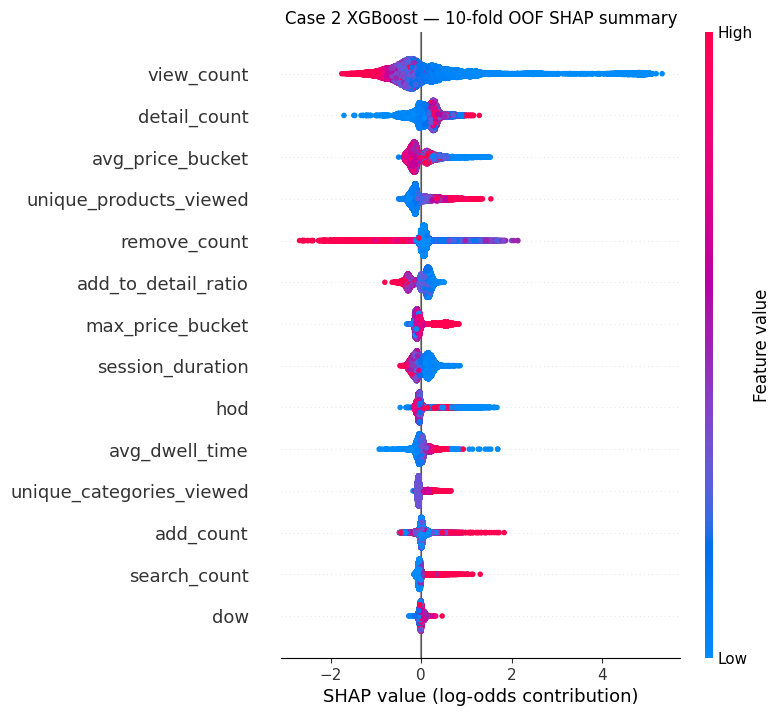

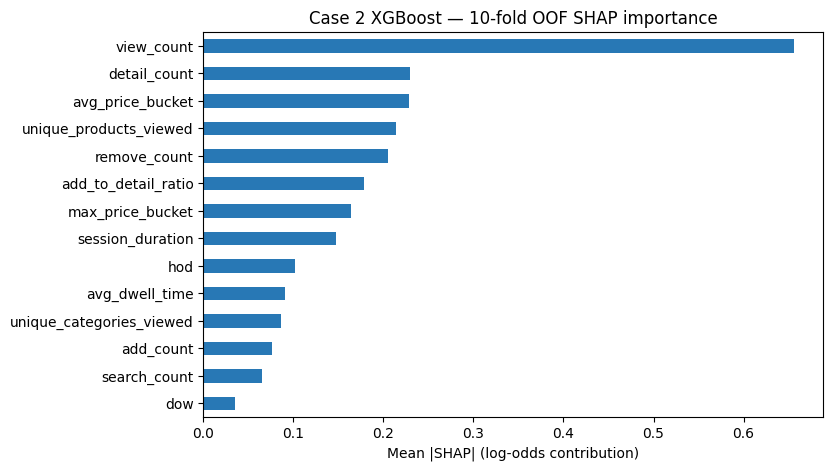

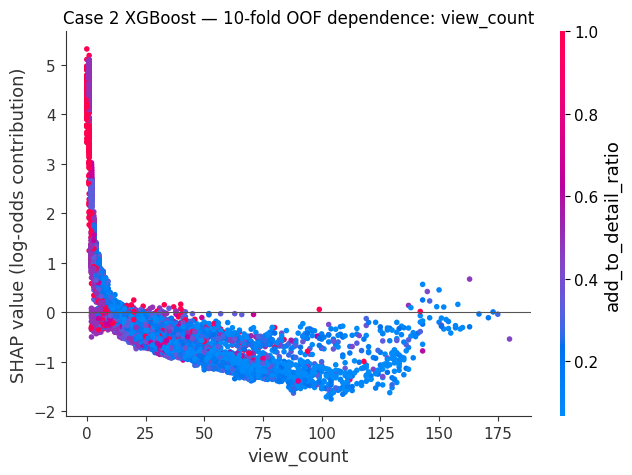

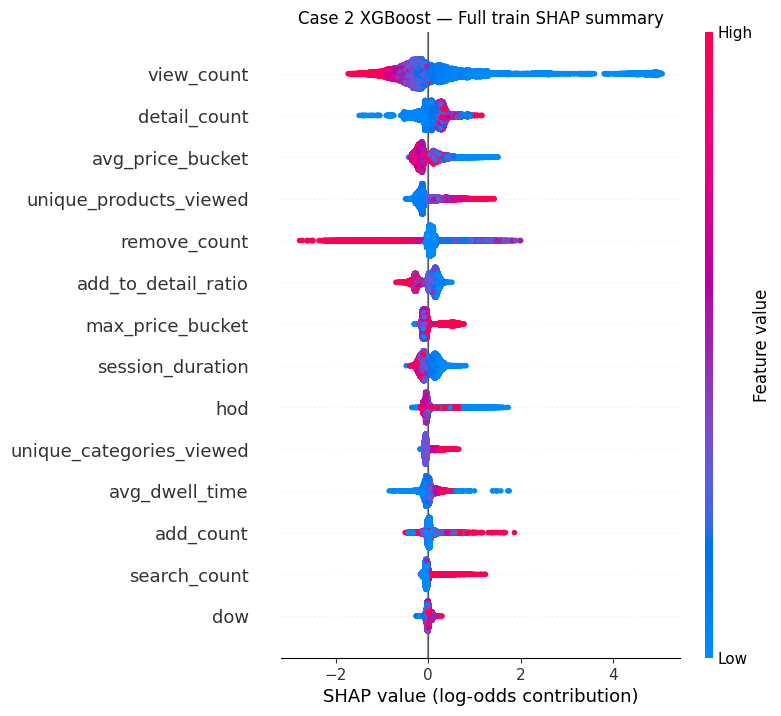

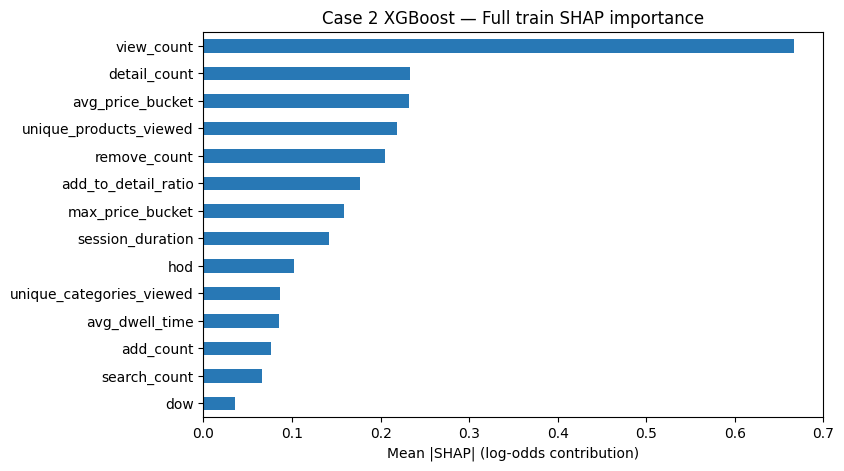

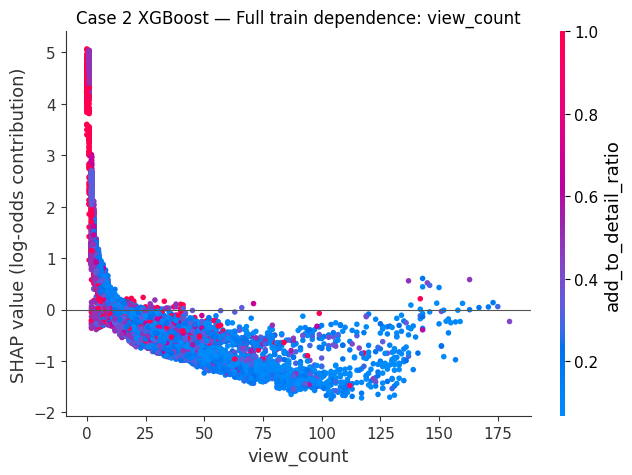

case2_xgb_tran_shap_full_train.csv.gz
case2_xgb_tran_shap_full_train_bar.png
case2_xgb_tran_shap_full_train_dependence_view_count.png
case2_xgb_tran_shap_full_train_importance.csv
case2_xgb_tran_shap_full_train_metadata.csv.gz
case2_xgb_tran_shap_full_train_summary.png
case2_xgb_tran_shap_full_train_values_X.csv.gz
case2_xgb_tran_shap_oof.csv.gz
case2_xgb_tran_shap_oof_bar.png
case2_xgb_tran_shap_oof_dependence_view_count.png
case2_xgb_tran_shap_oof_importance.csv
case2_xgb_tran_shap_oof_metadata.csv.gz
case2_xgb_tran_shap_oof_summary.png
case2_xgb_tran_shap_oof_values_X.csv.gz


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import shap


output_dir = Path("/kaggle/working/shap_figures")
output_dir.mkdir(parents=True, exist_ok=True)

full_X_imputed, full_contrib, full_margin = get_log_odds_contributions(
    best_model, X_train
)
full_proba = best_model.predict_proba(X_train)[:, 1]

# Dùng cùng mẫu để hai bộ biểu đồ có thể đối chiếu theo cùng các dòng.
rng = np.random.default_rng(42)
plot_idx = np.sort(
    rng.choice(len(X_train), size=min(30_000, len(X_train)), replace=False)
)


def export_shap_results(scope, title, X_imputed, contributions, margin, proba):
    prefix = output_dir / f"case2_xgb_tran_shap_{scope}"
    shap_df = pd.DataFrame(contributions[:, :-1], columns=features)
    values_df = pd.DataFrame(X_imputed, columns=features)

    # Hai CSV này giữ cùng hàng và cột, giống cặp CSV ở Case 1.
    shap_df.to_csv(f"{prefix}.csv.gz", index=False)
    values_df.to_csv(f"{prefix}_values_X.csv.gz", index=False)

    metadata = pd.DataFrame({
        "row_id": np.arange(len(X_train)),
        "SCA": y_train.to_numpy(),
        "bias_log_odds": contributions[:, -1],
        "prediction_log_odds": margin,
        "probability_sca_1": proba,
    })
    if scope == "oof":
        metadata.insert(1, "fold", fold_ids)
    metadata.to_csv(f"{prefix}_metadata.csv.gz", index=False)

    # Importance dùng toàn bộ dòng. Chỉ beeswarm và dependence lấy mẫu.
    importance = shap_df.abs().mean().sort_values(ascending=False)
    importance.rename_axis("feature").rename("mean_abs_shap").to_csv(
        f"{prefix}_importance.csv"
    )

    S_plot = shap_df.iloc[plot_idx].to_numpy()
    X_plot = values_df.iloc[plot_idx]

    shap.summary_plot(S_plot, X_plot, max_display=len(features), show=False)
    ax = plt.gca()
    ax.axvline(0, color="#555555", linewidth=0.8)
    ax.set_xlabel("SHAP value (log-odds contribution)")
    ax.set_title(f"Case 2 XGBoost — {title} SHAP summary")
    plt.savefig(f"{prefix}_summary.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    fig, ax = plt.subplots(figsize=(8, 5))
    importance.sort_values().plot.barh(ax=ax, color="#2878B5")
    ax.set_xlabel("Mean |SHAP| (log-odds contribution)")
    ax.set_title(f"Case 2 XGBoost — {title} SHAP importance")
    fig.savefig(f"{prefix}_bar.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    shap.dependence_plot(
        "view_count",
        S_plot,
        X_plot,
        interaction_index="add_to_detail_ratio",
        show=False,
    )
    ax = plt.gca()
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set_ylabel("SHAP value (log-odds contribution)")
    ax.set_title(f"Case 2 XGBoost — {title} dependence: view_count")
    plt.savefig(
        f"{prefix}_dependence_view_count.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


export_shap_results(
    "oof", "10-fold OOF", oof_X_imputed, oof_contrib, oof_margin, oof_proba
)
export_shap_results(
    "full_train", "Full train", full_X_imputed, full_contrib, full_margin, full_proba
)

for path in sorted(output_dir.iterdir()):
    print(path.name)

### `__notebook__.ipynb`

### `xgboost_tran.json`

{
  "case": "case2",
  "model": "xgboost",
  "author": "tran",
  "features": [
    "add_count",
    "remove_count",
    "view_count",
    "detail_count",
    "add_to_detail_ratio",
    "search_count",
    "unique_categories_viewed",
    "avg_price_bucket",
    "max_price_bucket",
    "unique_products_viewed",
    "avg_dwell_time",
    "session_duration",
    "hod",
    "dow"
  ],
  "n_features": 14,
  "split": "Fixed train_folds.csv (143771 rows) and test.csv (70814 rows); 10-fold PredefinedSplit; no row deletion",
  "best_params": {
    "subsample": 0.8,
    "reg_lambda": 1,
    "n_estimators": 500,
    "min_child_weight": 1,
    "max_depth": 6,
    "learning_rate": 0.03,
    "colsample_bytree": 0.9
  },
  "metrics_test": {
    "rmse": 0.37532801984322833,
    "mse": 0.14087112247943878,
    "mae": 0.28309357166290283,
    "r2": 0.1640545129776001,
    "roc_auc": 0.7736140089003719
  },
  "metrics_class": {
    "at_0.5": {
      "threshold": 0.5,
      "precision_1": 0.809034384598097

### `shap_figures/case2_xgb_tran_shap_full_train.csv.gz`

shape = (143771, 14)


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
0,0.188239,0.408340,-0.352702,0.021441,-0.322617,0.607477,-0.041889,-0.191331,-0.124646,-0.191359,-0.068249,-0.102777,-0.039442,0.032615
1,-0.046080,0.073780,-0.084555,0.145272,-0.098155,-0.058341,-0.043820,0.361217,-0.115784,-0.146336,0.194240,-0.099163,0.065732,0.080803
2,0.267546,0.770460,-0.461738,0.083302,0.174729,-0.000341,0.104720,0.342571,-0.065904,0.005160,0.010005,-0.120445,0.046107,-0.025557
3,0.190243,0.535953,-0.825020,0.239403,0.244128,-0.018253,-0.076172,0.250544,0.545428,0.055771,-0.107525,-0.142728,-0.057543,-0.074692
4,0.072184,0.024507,-1.168615,0.266386,0.170680,0.045175,0.180731,-0.236779,0.420870,0.198621,-0.076306,-0.267765,-0.137911,-0.034087
5,0.048731,-0.019670,-0.308902,-0.039315,-0.297895,-0.050228,-0.063381,-0.139814,-0.026353,-0.282882,-0.033436,-0.137916,-0.052168,-0.009428
6,-0.193723,0.523413,-0.673948,0.244194,0.180799,-0.018810,0.064206,0.122858,-0.152874,0.213786,-0.069062,-0.090869,-0.058911,-0.002997
7,0.035116,0.045496,-0.456649,0.240056,0.231457,0.026223,0.183175,0.150142,0.493955,-0.102048,0.229652,-0.131293,0.008466,0.000101
8,0.023808,0.025381,-0.051446,0.312956,0.231241,-0.038084,0.231530,-0.331167,-0.096980,0.047466,-0.109192,0.209777,-0.032274,-0.070804
9,-0.008504,0.048130,0.426062,0.349159,0.166795,-0.048248,-0.075088,-0.307600,-0.081090,0.018186,-0.087282,0.215124,0.058921,0.043071


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
143766,-0.006192,0.051032,0.602380,-0.300784,-0.247335,0.026521,-0.056105,-0.161843,-0.106898,-0.137199,0.471933,-0.056190,-0.037116,-0.028312
143767,0.039401,0.000719,-0.105604,0.341238,0.092985,-0.048373,-0.067501,0.052392,0.481876,-0.268500,0.061306,-0.218225,0.220016,0.043592
143768,0.079872,0.025842,-0.049898,-0.182951,-0.395063,-0.018143,-0.053250,-0.156553,-0.129848,-0.228426,-0.036183,0.109188,-0.090529,0.009665
143769,0.054684,0.104938,0.245200,0.073214,0.153331,-0.040787,-0.058711,0.361680,-0.097350,-0.225633,0.038123,0.118772,0.266455,-0.031044
143770,0.150902,0.089683,-0.325404,0.205866,0.254917,-0.026565,-0.063553,1.304311,-0.157881,-0.077243,-0.040211,0.070063,-0.048142,-0.014795


,count,mean,std,min,25%,50%,75%,max
add_count,143771.0,0.026723,0.127587,-0.519364,-0.011568,0.014941,0.058061,1.875433
remove_count,143771.0,0.055181,0.412008,-2.848984,0.018907,0.060764,0.109415,2.011793
view_count,143771.0,0.164662,1.114437,-1.835893,-0.416513,-0.110762,0.379565,5.065993
detail_count,143771.0,0.110457,0.271330,-1.508080,-0.057079,0.126236,0.280615,1.327220
add_to_detail_ratio,143771.0,0.006924,0.204829,-0.702432,-0.197714,0.083911,0.165920,0.512287
search_count,143771.0,-0.012512,0.110139,-0.236608,-0.055373,-0.035942,-0.013126,1.238306
unique_categories_viewed,143771.0,-0.001592,0.113077,-0.181283,-0.067569,-0.051296,0.008857,0.775540
avg_price_bucket,143771.0,0.013579,0.300404,-0.446329,-0.196347,-0.107903,0.168342,1.536927
max_price_bucket,143771.0,0.034157,0.233175,-0.307593,-0.103716,-0.063158,-0.008066,0.774663
unique_products_viewed,143771.0,0.002547,0.279438,-0.523869,-0.180921,-0.120035,0.124020,1.465082


### `shap_figures/case2_xgb_tran_shap_full_train_bar.png`

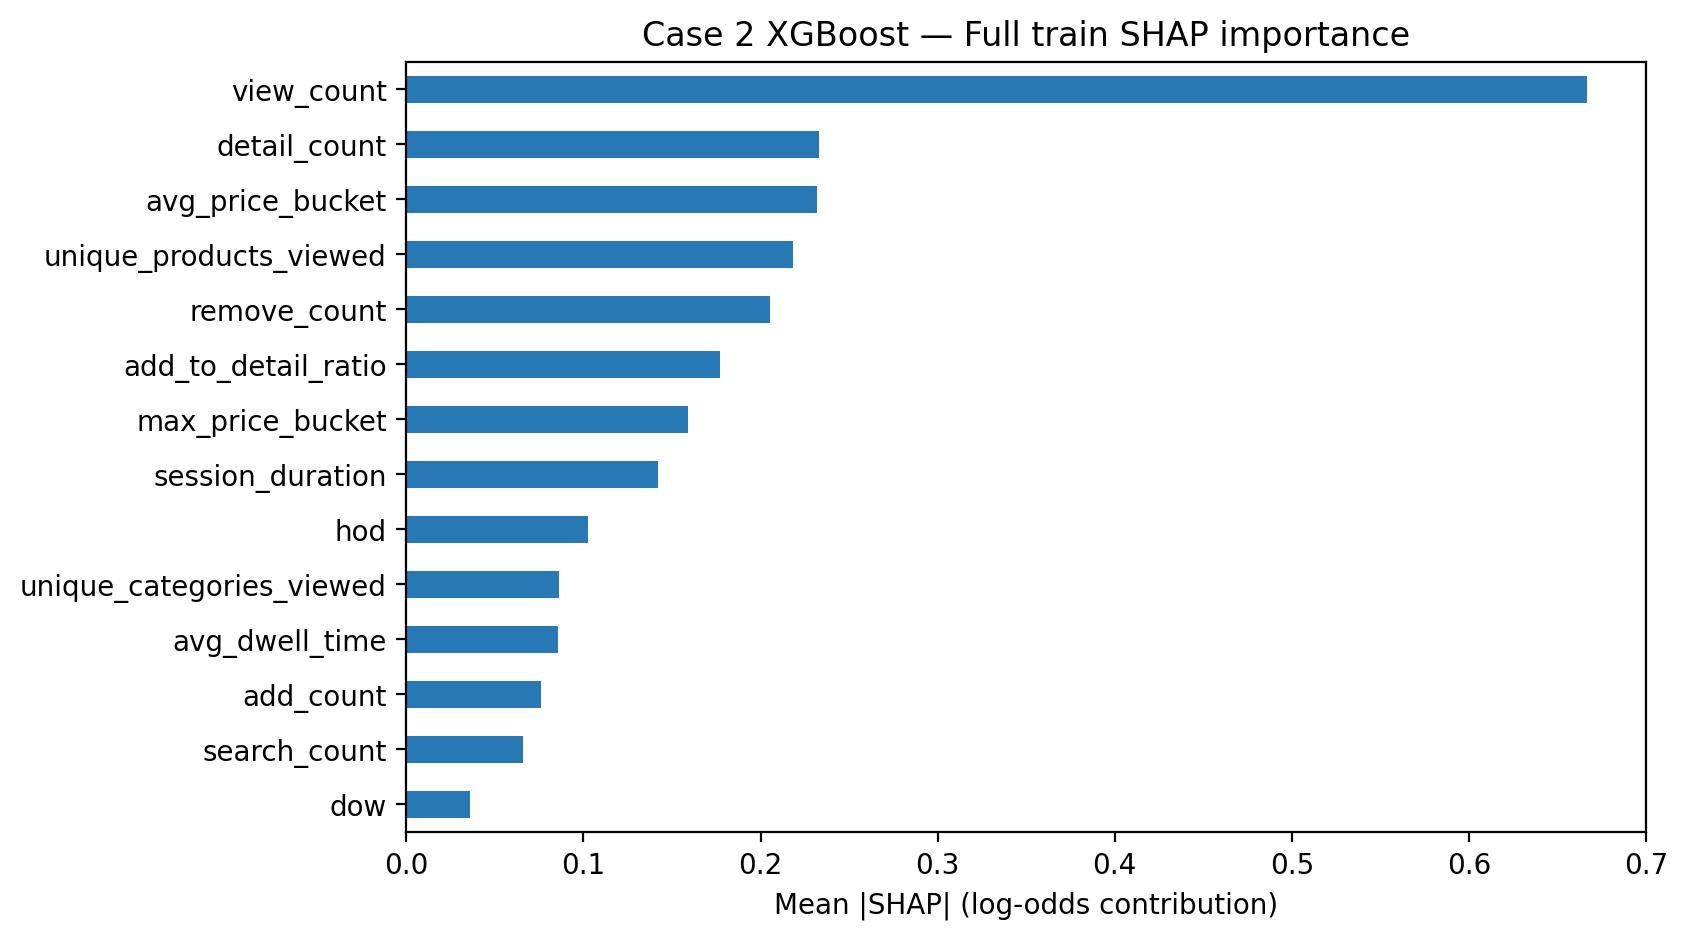

### `shap_figures/case2_xgb_tran_shap_full_train_dependence_view_count.png`

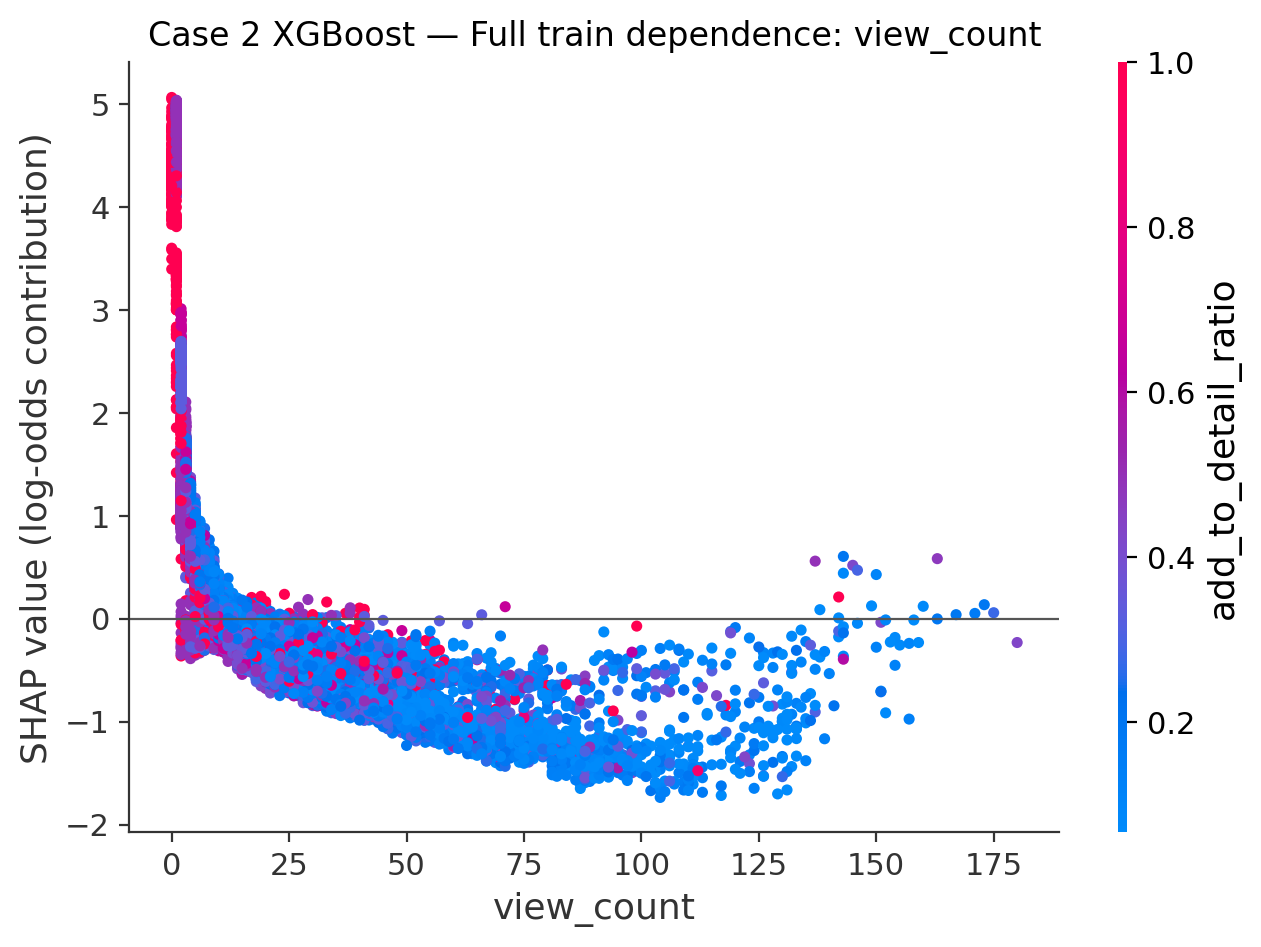

### `shap_figures/case2_xgb_tran_shap_full_train_importance.csv`

shape = (14, 1)


,mean_abs_shap
feature,
view_count,0.666850
detail_count,0.233195
avg_price_bucket,0.232126
unique_products_viewed,0.218174
remove_count,0.205386
add_to_detail_ratio,0.177071
max_price_bucket,0.159030
session_duration,0.142091
hod,0.102483


### `shap_figures/case2_xgb_tran_shap_full_train_metadata.csv.gz`

shape = (143771, 4)


,SCA,bias_log_odds,prediction_log_odds,probability_sca_1
row_id,,,,
0,0,1.302865,1.125964,0.755093
1,0,1.302865,1.531672,0.822251
2,1,1.302865,2.433478,0.919345
3,1,1.302865,2.062404,0.887195
4,0,1.302865,0.760557,0.681475
5,0,1.302865,-0.109793,0.472579
6,1,1.302865,1.390924,0.800740
7,1,1.302865,2.256712,0.905228
8,1,1.302865,1.655078,0.839576


,SCA,bias_log_odds,prediction_log_odds,probability_sca_1
row_id,,,,
143766,1,1.302865,1.316755,0.788641
143767,1,1.302865,1.928188,0.873049
143768,1,1.302865,0.186588,0.546512
143769,1,1.302865,2.265733,0.905999
143770,1,1.302865,2.624814,0.932442


,count,mean,std,min,25%,50%,75%,max
SCA,143771.0,0.785450,4.105109e-01,0.000000,1.000000,1.000000,1.000000,1.000000
bias_log_odds,143771.0,1.302865,3.053790e-12,1.302865,1.302865,1.302865,1.302865,1.302865
prediction_log_odds,143771.0,1.745569,1.465490e+00,-2.845832,0.778722,1.494058,2.377539,8.119404
probability_sca_1,143771.0,0.785417,1.629170e-01,0.054897,0.685405,0.816686,0.915099,0.999702


### `shap_figures/case2_xgb_tran_shap_full_train_summary.png`

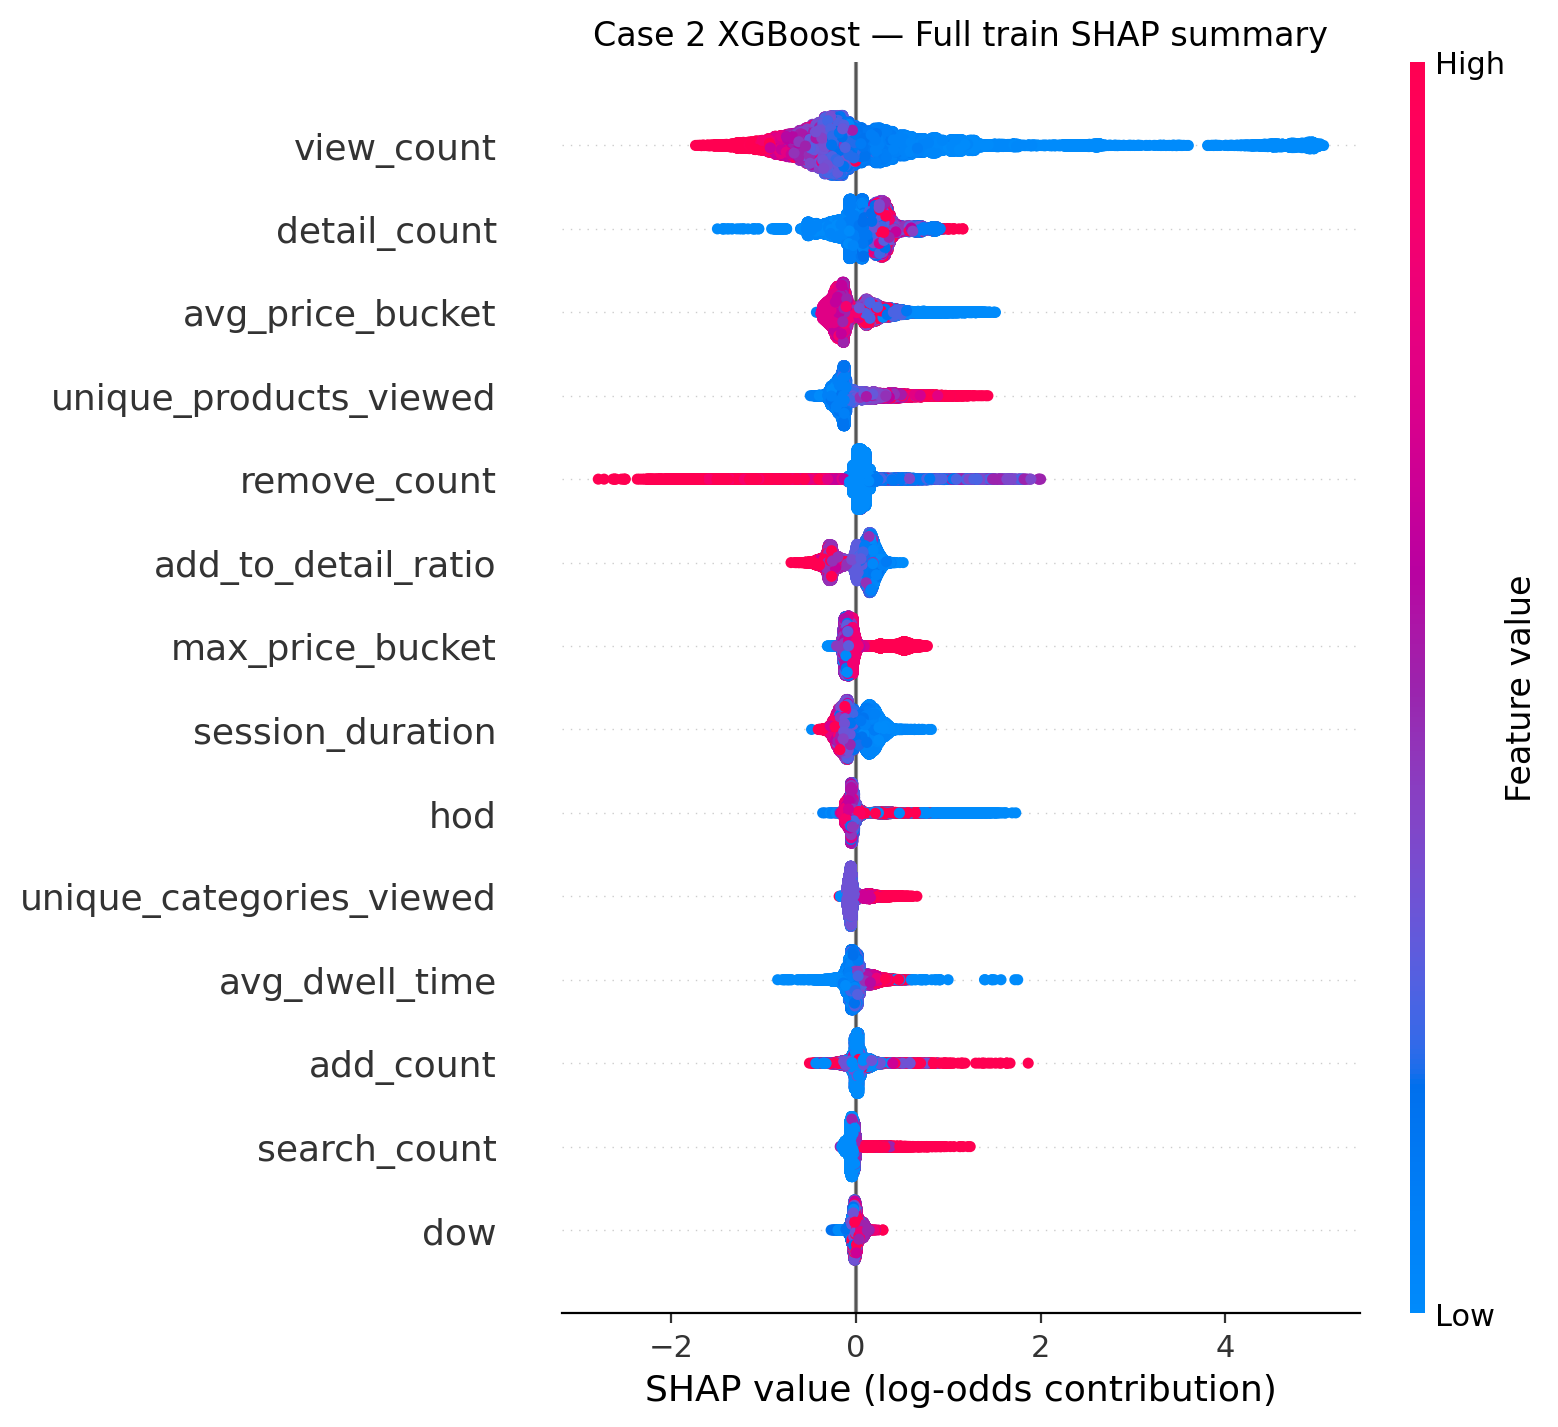

### `shap_figures/case2_xgb_tran_shap_full_train_values_X.csv.gz`

shape = (143771, 14)


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
0,1.0,1.0,24.0,0.0,1.000000,5.0,0.0,7.0,7.0,0.0,30.422320,760.558,12.0,4.0
1,2.0,0.0,10.0,4.0,0.400000,0.0,1.0,3.0,3.0,2.0,95.361364,1048.975,7.0,4.0
2,1.0,3.0,26.0,4.0,0.200000,1.0,2.0,4.0,8.0,4.0,41.664793,1208.279,7.0,3.0
3,1.0,1.0,43.0,18.0,0.052632,0.0,1.0,10.0,10.0,5.0,21.466091,944.508,9.0,2.0
4,1.0,0.0,67.0,10.0,0.090909,2.0,3.0,8.0,10.0,9.0,28.922493,1937.807,20.0,7.0
5,3.0,0.0,13.0,2.0,1.000000,0.0,1.0,9.0,9.0,1.0,61.436867,921.553,12.0,7.0
6,3.0,3.0,31.0,17.0,0.166667,0.0,2.0,4.0,5.0,7.0,24.794250,892.593,16.0,1.0
7,1.0,0.0,22.0,8.0,0.111111,1.0,2.0,10.0,10.0,3.0,142.303136,3130.669,18.0,1.0
8,1.0,0.0,12.0,6.0,0.142857,0.0,2.0,8.0,8.0,4.0,12.542083,150.505,14.0,2.0
9,1.0,0.0,6.0,5.0,0.166667,0.0,1.0,8.0,8.0,4.0,15.540000,93.240,21.0,5.0


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
143766,1.0,0.0,4.0,0.0,1.000,1.0,0.0,7.0,7.0,0.0,378.539500,1514.158,14.0,7.0
143767,2.0,0.0,13.0,7.0,0.250,0.0,1.0,10.0,10.0,2.0,94.549214,1323.689,22.0,5.0
143768,2.0,0.0,9.0,1.0,1.000,1.0,1.0,7.0,7.0,1.0,25.035200,250.352,17.0,7.0
143769,1.0,0.0,7.0,3.0,0.250,0.0,1.0,4.0,4.0,1.0,46.977286,328.841,22.0,3.0
143770,1.0,0.0,19.0,7.0,0.125,0.0,1.0,1.0,1.0,3.0,22.557947,428.601,14.0,3.0


,count,mean,std,min,25%,50%,75%,max
add_count,143771.0,1.529154,1.183741,1.000000,1.000000,1.000000,2.000000,28.000
remove_count,143771.0,1.348130,5.173681,0.000000,0.000000,0.000000,0.000000,185.000
view_count,143771.0,18.278930,19.298515,0.000000,6.000000,12.000000,24.000000,196.000
detail_count,143771.0,6.259746,8.087753,0.000000,1.000000,3.000000,8.000000,98.000
add_to_detail_ratio,143771.0,0.373421,0.367862,0.010638,0.166667,0.300000,0.500000,22.000
search_count,143771.0,0.487769,1.190422,0.000000,0.000000,0.000000,1.000000,44.000
unique_categories_viewed,143771.0,1.337572,0.969126,0.000000,1.000000,1.000000,1.000000,17.000
avg_price_bucket,143771.0,6.774241,2.378984,1.000000,5.000000,7.000000,9.000000,10.000
max_price_bucket,143771.0,7.496741,2.181280,1.000000,6.000000,8.000000,9.000000,10.000
unique_products_viewed,143771.0,3.841853,4.767314,0.000000,1.000000,2.000000,5.000000,88.000


### `shap_figures/case2_xgb_tran_shap_oof.csv.gz`

shape = (143771, 14)


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
0,0.181111,0.392279,-0.378959,-0.027080,-0.266367,0.612383,-0.041064,-0.184933,-0.122503,-0.187672,-0.043196,-0.092893,-0.013460,0.059448
1,-0.031797,0.072868,-0.081600,0.147038,-0.116145,-0.045754,-0.049307,0.378387,-0.118195,-0.149386,0.202124,-0.113377,0.056926,0.085264
2,0.219133,0.739292,-0.414143,0.109406,0.186542,-0.002913,0.091691,0.348813,-0.070223,0.004883,-0.012892,-0.139869,0.029924,-0.030419
3,0.175380,0.533572,-0.782368,0.237402,0.251286,-0.019914,-0.071527,0.227861,0.587841,0.037117,-0.107976,-0.167624,-0.055444,-0.055829
4,0.091807,0.033708,-1.138416,0.270320,0.184149,0.055977,0.219964,-0.254383,0.435539,0.141616,-0.092047,-0.298008,-0.138163,-0.036806
5,0.047901,-0.010424,-0.298117,-0.026940,-0.277301,-0.040085,-0.071250,-0.117206,-0.047030,-0.292920,0.006140,-0.144047,-0.051944,-0.037528
6,-0.217402,0.492634,-0.593399,0.240291,0.185084,-0.021243,0.074041,0.159974,-0.151695,0.191432,-0.072549,-0.051542,-0.067644,-0.016665
7,0.042865,0.027403,-0.460245,0.245317,0.229505,0.021795,0.164735,0.107631,0.542151,-0.094063,0.248605,-0.212959,-0.012499,0.000708
8,0.022442,0.025071,-0.123741,0.310277,0.227722,-0.035091,0.208894,-0.349140,-0.090845,0.065097,-0.092261,0.201885,-0.039826,-0.066658
9,-0.013888,0.048344,0.385116,0.313893,0.131951,-0.043832,-0.068609,-0.321412,-0.090040,-0.025462,-0.112801,0.181058,0.015219,0.034576


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
143766,-0.002620,0.047742,0.529123,-0.271282,-0.206446,0.013928,-0.056802,-0.161537,-0.103069,-0.177986,0.471661,-0.061939,-0.024594,-0.021756
143767,0.046047,0.030549,-0.047525,0.320520,0.121962,-0.045526,-0.068437,0.069113,0.511989,-0.264431,0.074409,-0.275813,0.208534,0.037832
143768,0.064476,0.030256,-0.050835,-0.178581,-0.405664,-0.009857,-0.049735,-0.150175,-0.136505,-0.229302,-0.040800,0.097536,-0.067771,0.010804
143769,0.050358,0.101682,0.220590,0.065971,0.155281,-0.041476,-0.048237,0.335532,-0.092065,-0.201365,0.068527,0.120922,0.270586,-0.031663
143770,0.128352,0.100880,-0.301958,0.191221,0.343544,-0.024002,-0.058982,1.388760,-0.140026,-0.086175,-0.036547,0.084026,-0.039573,-0.005316


,count,mean,std,min,25%,50%,75%,max
add_count,143771.0,0.023577,0.127681,-0.485455,-0.015528,0.012277,0.056341,1.943069
remove_count,143771.0,0.054922,0.410731,-2.843401,0.018973,0.060428,0.108726,2.133515
view_count,143771.0,0.162963,1.102027,-1.755001,-0.408393,-0.114016,0.370913,5.319659
detail_count,143771.0,0.114760,0.265296,-1.703794,-0.043140,0.132083,0.280703,1.376172
add_to_detail_ratio,143771.0,0.002625,0.207259,-0.801930,-0.203646,0.081076,0.166046,0.513857
search_count,143771.0,-0.010686,0.110178,-0.189848,-0.054576,-0.034728,-0.012961,1.303763
unique_categories_viewed,143771.0,-0.000122,0.113576,-0.181148,-0.066878,-0.049893,0.008449,0.762696
avg_price_bucket,143771.0,0.016133,0.298602,-0.498295,-0.189658,-0.100796,0.165482,1.620944
max_price_bucket,143771.0,0.033890,0.239190,-0.363301,-0.106276,-0.065653,-0.007678,0.853188
unique_products_viewed,143771.0,0.000745,0.274863,-0.528490,-0.180063,-0.113974,0.118024,1.538684


### `shap_figures/case2_xgb_tran_shap_oof_bar.png`

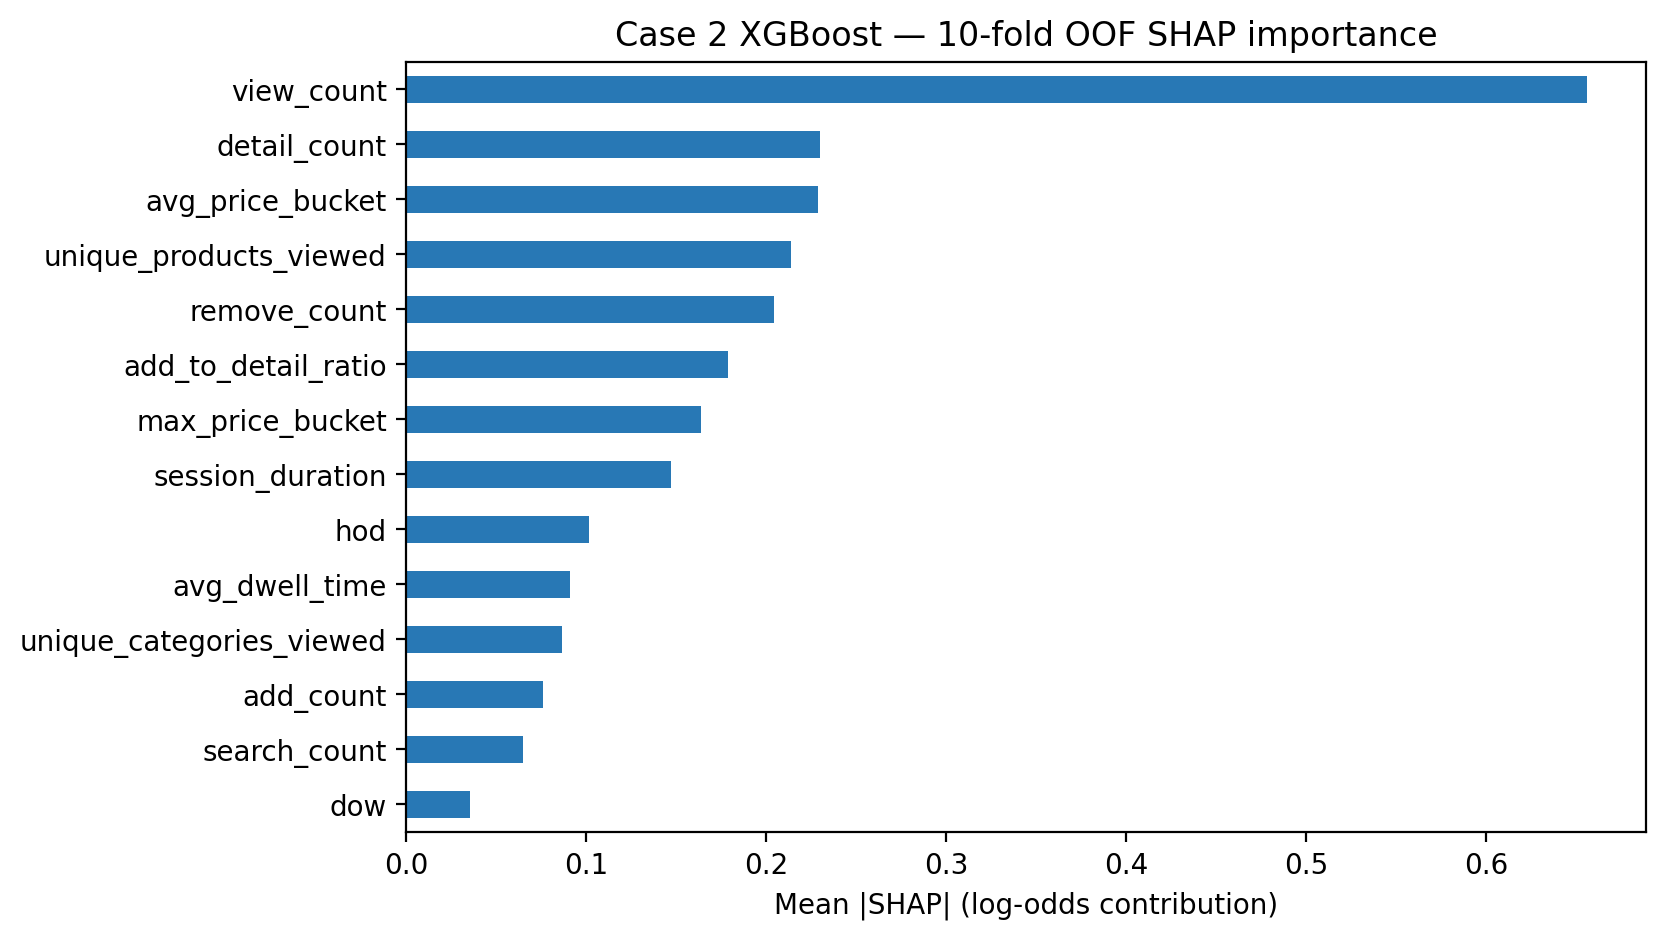

### `shap_figures/case2_xgb_tran_shap_oof_dependence_view_count.png`

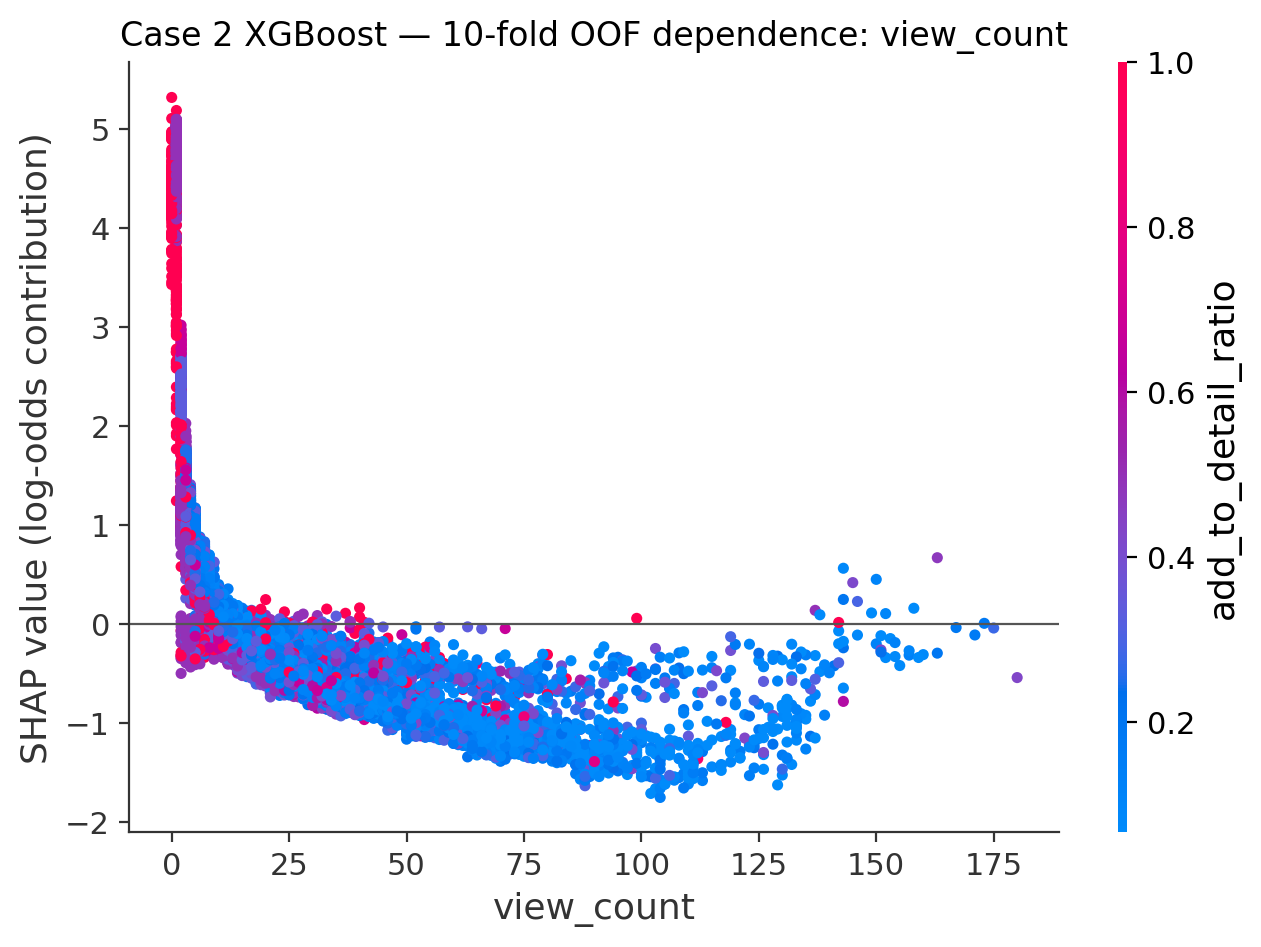

### `shap_figures/case2_xgb_tran_shap_oof_importance.csv`

shape = (14, 1)


,mean_abs_shap
feature,
view_count,0.656044
detail_count,0.229849
avg_price_bucket,0.228487
unique_products_viewed,0.213847
remove_count,0.204520
add_to_detail_ratio,0.178736
max_price_bucket,0.163479
session_duration,0.147127
hod,0.101614


### `shap_figures/case2_xgb_tran_shap_oof_metadata.csv.gz`

shape = (143771, 5)


,fold,SCA,bias_log_odds,prediction_log_odds,probability_sca_1
row_id,,,,,
0,9,0,1.302668,1.189763,0.766699
1,6,0,1.303142,1.540186,0.823492
2,6,1,1.303142,2.362364,0.913912
3,7,1,1.303611,2.093388,0.890259
4,5,0,1.303276,0.778534,0.685364
5,0,0,1.302966,-0.057786,0.485557
6,5,1,1.303276,1.454592,0.810704
7,5,1,1.303276,2.154227,0.896063
8,5,1,1.303276,1.567102,0.827370


,fold,SCA,bias_log_odds,prediction_log_odds,probability_sca_1
row_id,,,,,
143766,8,1,1.302614,1.277036,0.781945
143767,9,1,1.302668,2.021889,0.883076
143768,7,1,1.303611,0.187455,0.546727
143769,7,1,1.303611,2.278250,0.907060
143770,4,1,1.303293,2.847495,0.945189


,count,mean,std,min,25%,50%,75%,max
fold,143771.0,4.499969,2.872306,0.000000,2.000000,4.000000,7.000000,9.000000
SCA,143771.0,0.785450,0.410511,0.000000,1.000000,1.000000,1.000000,1.000000
bias_log_odds,143771.0,1.303050,0.000297,1.302614,1.302771,1.302966,1.303276,1.303611
prediction_log_odds,143771.0,1.743854,1.456833,-2.936654,0.783861,1.493008,2.370894,8.077437
probability_sca_1,143771.0,0.785807,0.161951,0.050371,0.686512,0.816529,0.914581,0.999690


### `shap_figures/case2_xgb_tran_shap_oof_summary.png`

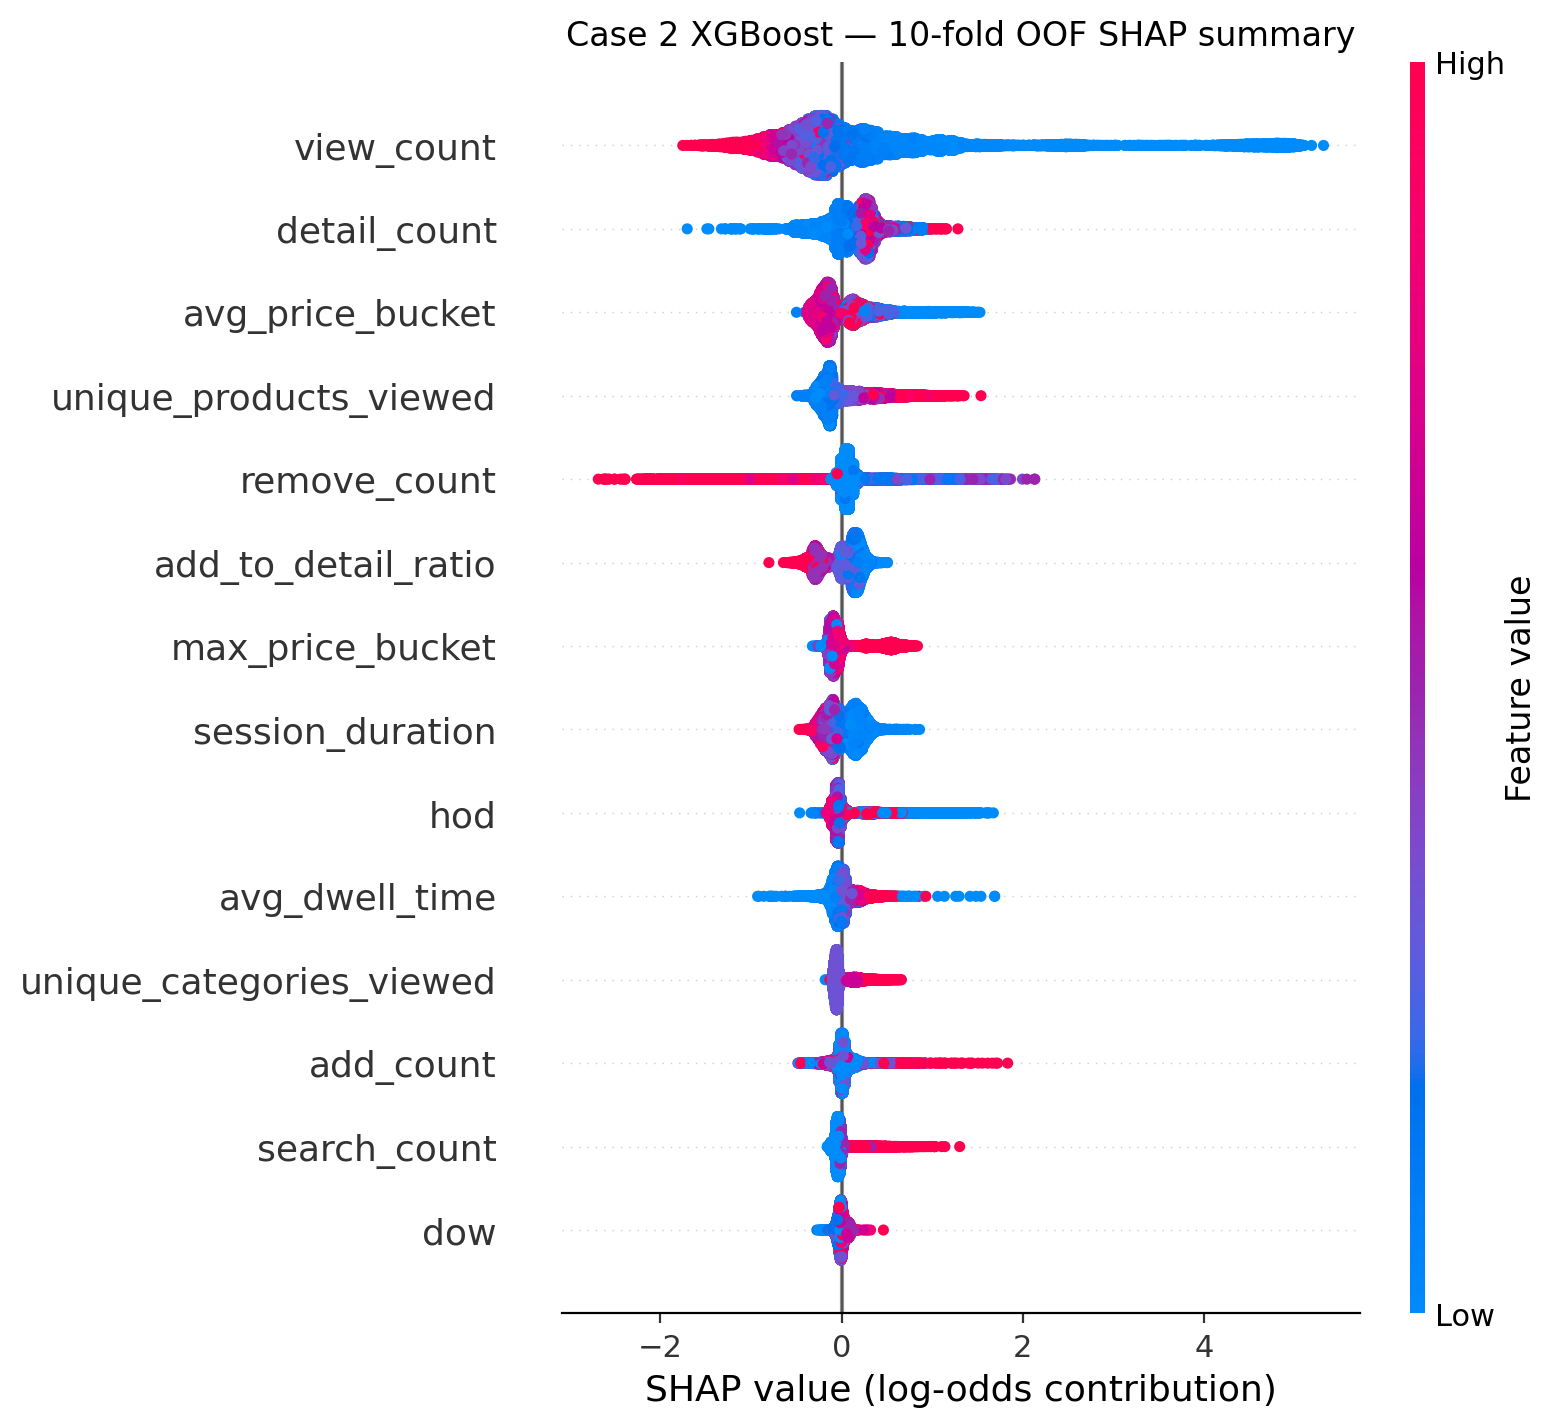

### `shap_figures/case2_xgb_tran_shap_oof_values_X.csv.gz`

shape = (143771, 14)


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
0,1.0,1.0,24.0,0.0,1.000000,5.0,0.0,7.0,7.0,0.0,30.422320,760.558,12.0,4.0
1,2.0,0.0,10.0,4.0,0.400000,0.0,1.0,3.0,3.0,2.0,95.361364,1048.975,7.0,4.0
2,1.0,3.0,26.0,4.0,0.200000,1.0,2.0,4.0,8.0,4.0,41.664793,1208.279,7.0,3.0
3,1.0,1.0,43.0,18.0,0.052632,0.0,1.0,10.0,10.0,5.0,21.466091,944.508,9.0,2.0
4,1.0,0.0,67.0,10.0,0.090909,2.0,3.0,8.0,10.0,9.0,28.922493,1937.807,20.0,7.0
5,3.0,0.0,13.0,2.0,1.000000,0.0,1.0,9.0,9.0,1.0,61.436867,921.553,12.0,7.0
6,3.0,3.0,31.0,17.0,0.166667,0.0,2.0,4.0,5.0,7.0,24.794250,892.593,16.0,1.0
7,1.0,0.0,22.0,8.0,0.111111,1.0,2.0,10.0,10.0,3.0,142.303136,3130.669,18.0,1.0
8,1.0,0.0,12.0,6.0,0.142857,0.0,2.0,8.0,8.0,4.0,12.542083,150.505,14.0,2.0
9,1.0,0.0,6.0,5.0,0.166667,0.0,1.0,8.0,8.0,4.0,15.540000,93.240,21.0,5.0


,add_count,remove_count,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,unique_products_viewed,avg_dwell_time,session_duration,hod,dow
143766,1.0,0.0,4.0,0.0,1.000,1.0,0.0,7.0,7.0,0.0,378.539500,1514.158,14.0,7.0
143767,2.0,0.0,13.0,7.0,0.250,0.0,1.0,10.0,10.0,2.0,94.549214,1323.689,22.0,5.0
143768,2.0,0.0,9.0,1.0,1.000,1.0,1.0,7.0,7.0,1.0,25.035200,250.352,17.0,7.0
143769,1.0,0.0,7.0,3.0,0.250,0.0,1.0,4.0,4.0,1.0,46.977286,328.841,22.0,3.0
143770,1.0,0.0,19.0,7.0,0.125,0.0,1.0,1.0,1.0,3.0,22.557947,428.601,14.0,3.0


,count,mean,std,min,25%,50%,75%,max
add_count,143771.0,1.529154,1.183741,1.000000,1.000000,1.000000,2.000000,28.000
remove_count,143771.0,1.348130,5.173681,0.000000,0.000000,0.000000,0.000000,185.000
view_count,143771.0,18.278930,19.298515,0.000000,6.000000,12.000000,24.000000,196.000
detail_count,143771.0,6.259746,8.087753,0.000000,1.000000,3.000000,8.000000,98.000
add_to_detail_ratio,143771.0,0.373421,0.367862,0.010638,0.166667,0.300000,0.500000,22.000
search_count,143771.0,0.487769,1.190422,0.000000,0.000000,0.000000,1.000000,44.000
unique_categories_viewed,143771.0,1.337572,0.969126,0.000000,1.000000,1.000000,1.000000,17.000
avg_price_bucket,143771.0,6.774241,2.378984,1.000000,5.000000,7.000000,9.000000,10.000
max_price_bucket,143771.0,7.496741,2.181280,1.000000,6.000000,8.000000,9.000000,10.000
unique_products_viewed,143771.0,3.841853,4.767314,0.000000,1.000000,2.000000,5.000000,88.000


In [10]:
import os, json
import pandas as pd
from IPython.display import display, Image, Markdown

root = "/kaggle/working"
skip_dirs = {".virtual_documents", "repo_tmp", ".git"}

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

MAX_ROWS_FULL = 200

for dirpath, dirnames, filenames in os.walk(root):
    dirnames[:] = [d for d in dirnames if d not in skip_dirs]
    for fn in sorted(filenames):
        path = os.path.join(dirpath, fn)
        rel = os.path.relpath(path, root)
        display(Markdown(f"### `{rel}`"))

        if fn.lower().endswith((".png", ".jpg", ".jpeg")):
            display(Image(filename=path))

        elif fn.lower().endswith((".csv", ".csv.gz")):
            has_index = any(k in fn for k in ("metadata", "importance"))
            df = pd.read_csv(path, sep=None, engine="python",
                             index_col=0 if has_index else None)
            print(f"shape = {df.shape}")
            if len(df) <= MAX_ROWS_FULL:
                display(df)
            else:
                display(df.head(10))
                display(df.tail(5))
                display(df.describe().T)

        elif fn.lower().endswith(".json"):
            print(json.dumps(json.load(open(path)), indent=2, ensure_ascii=False))

In [11]:
import pandas as pd
from IPython.display import display

p_test = best_model.predict_proba(test[features])[:, 1]

out = pd.DataFrame({
    "row_id": test.index,
    "p_test": p_test,
})
if "SCA" in test.columns:
    out["SCA"] = test["SCA"].values

out.to_csv("/kaggle/working/case2_xgb_tran_p_test.csv", index=False)

# ---- in kết quả ----
print(f"shape = {out.shape}")
display(out.head(10))
display(out.tail(5))
display(out["p_test"].describe())

shape = (70814, 3)


,row_id,p_test,SCA
0,0,0.621536,0
1,1,0.415551,0
2,2,0.744735,1
3,3,0.767137,1
4,4,0.934272,1
5,5,0.978714,1
6,6,0.738499,0
7,7,0.826584,1
8,8,0.988156,1
9,9,0.570415,0


,row_id,p_test,SCA
70809,70809,0.826727,0
70810,70810,0.676890,0
70811,70811,0.806094,1
70812,70812,0.975931,1
70813,70813,0.888859,1


count    70814.000000
mean         0.785355
std          0.162328
min          0.069089
25%          0.685710
50%          0.816785
75%          0.914630
max          0.999608
Name: p_test, dtype: float64